Objective
This project aims to develop an Intelligent Routing Agent using the Chicago Traffic Tracker dataset. The agent will analyze historical and real-time segment speeds to identify the fastest routes for users within a dynamic road network.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Source

In [ ]:
# Use the path you provided earlier
file_path = "/content/drive/MyDrive/CA6001/Chicago_Traffic_Tracker_2024-Current_20260427.csv"
# file_path = "/content/drive/MyDrive/CA6001/Chicago_Traffic_Tracker_whole_year_2024_Jul_Dec.csv"

# file_path = "/content/drive/MyDrive/CA6001/Chicago_Traffic_Tracker_whole_year_2024_full.csv"

## Model Training

Loading full-year dataset...
Performing feature engineering...
Calculating Precise Temporal Baselines...
[0]	validation_0-rmse:6.90562	validation_1-rmse:6.85467
[118]	validation_0-rmse:3.42590	validation_1-rmse:4.24278


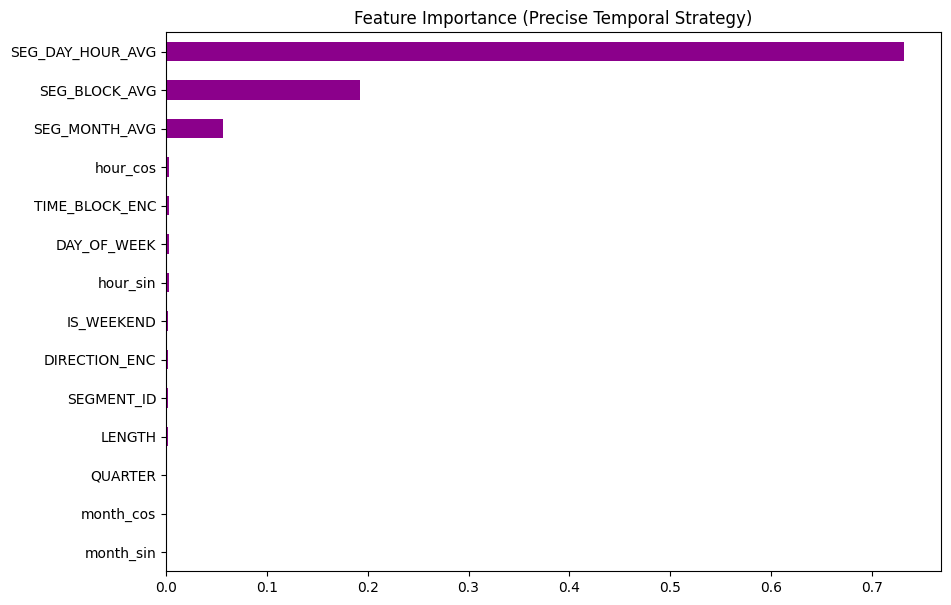


  FINAL PRECISION-OPTIMIZED MODEL REPORT  
MAE:  3.18 mph
RMSE: 4.23 mph
R2:   0.6329


['chicago_speed_precision_final.pkl']

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
import joblib

# ---------------------------------------------------------
# Step 1: Load Dataset
# ---------------------------------------------------------

print("Loading full-year dataset...")
df = pd.read_csv(file_path)

# Data Cleaning
df = df[df['SPEED'] > 0].copy()
df['TIME'] = pd.to_datetime(df['TIME'])
df = df.sort_values('TIME').reset_index(drop=True)

# ---------------------------------------------------------
# Step 2: Advanced Feature Engineering
# ---------------------------------------------------------
def get_time_block(hour):
    if 0 <= hour < 6: return 'Overnight'
    elif 6 <= hour < 10: return 'Morning_Rush'
    elif 10 <= hour < 15: return 'Midday'
    elif 15 <= hour < 19: return 'Evening_Rush'
    else: return 'Evening'

def engineering_features(df):
    print("Performing feature engineering...")

    # 1. Basic time components
    df['HOUR'] = df['TIME'].dt.hour
    df['DAY_OF_WEEK'] = df['TIME'].dt.dayofweek
    df['MONTH'] = df['TIME'].dt.month
    df['QUARTER'] = df['TIME'].dt.quarter
    df['IS_WEEKEND'] = (df['DAY_OF_WEEK'] >= 5).astype(int)

    # 2. Functional Time Blocks
    df['TIME_BLOCK'] = df['HOUR'].apply(get_time_block)

    # 3. Cyclical Encoding
    df['hour_sin'] = np.sin(2 * np.pi * df['HOUR'] / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * df['HOUR'] / 24.0)
    df['month_sin'] = np.sin(2 * np.pi * df['MONTH'] / 12.0)
    df['month_cos'] = np.cos(2 * np.pi * df['MONTH'] / 12.0)

    # 4. Label Encoding
    le_dir = LabelEncoder()
    df['DIRECTION_ENC'] = le_dir.fit_transform(df['DIRECTION'].astype(str))

    le_block = LabelEncoder()
    df['TIME_BLOCK_ENC'] = le_block.fit_transform(df['TIME_BLOCK'])

    return df

df = engineering_features(df)

# ---------------------------------------------------------
# Step 3: Temporal Split & Precision Target Encoding
# ---------------------------------------------------------
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

print("Calculating Precise Temporal Baselines...")

# A. Segment + Day + Hour Mean (The most precise baseline)
day_hour_stats = train_df.groupby(['SEGMENT_ID', 'DAY_OF_WEEK', 'HOUR'])['SPEED'].mean().reset_index()
day_hour_stats.rename(columns={'SPEED': 'SEG_DAY_HOUR_AVG'}, inplace=True)

# B. Block-Based Mean (Fallback Level 1)
block_stats = train_df.groupby(['SEGMENT_ID', 'TIME_BLOCK'])['SPEED'].mean().reset_index()
block_stats.rename(columns={'SPEED': 'SEG_BLOCK_AVG'}, inplace=True)

# C. Monthly-Based Mean (Seasonality Baseline)
month_stats = train_df.groupby(['SEGMENT_ID', 'MONTH'])['SPEED'].mean().reset_index()
month_stats.rename(columns={'SPEED': 'SEG_MONTH_AVG'}, inplace=True)

# D. Global Fallbacks
segment_stats = train_df.groupby('SEGMENT_ID')['SPEED'].mean().to_dict()
global_mean = train_df['SPEED'].mean()

# Merge features into Train/Test
def merge_all_stats(target_df):
    target_df = target_df.merge(day_hour_stats, on=['SEGMENT_ID', 'DAY_OF_WEEK', 'HOUR'], how='left')
    target_df = target_df.merge(block_stats, on=['SEGMENT_ID', 'TIME_BLOCK'], how='left')
    target_df = target_df.merge(month_stats, on=['SEGMENT_ID', 'MONTH'], how='left')

    # Fill missing values using a hierarchy of precision:
    # 1. If Day-Hour is missing, use Block Avg
    # 2. If Block Avg is missing, use Month Avg
    # 3. If Month Avg is missing, use Segment Avg
    # 4. Final fallback: Global Mean
    target_df['SEG_DAY_HOUR_AVG'] = target_df['SEG_DAY_HOUR_AVG'].fillna(target_df['SEG_BLOCK_AVG'])
    target_df['SEG_DAY_HOUR_AVG'] = target_df['SEG_DAY_HOUR_AVG'].fillna(target_df['SEGMENT_ID'].map(segment_stats)).fillna(global_mean)

    target_df['SEG_BLOCK_AVG'] = target_df['SEG_BLOCK_AVG'].fillna(target_df['SEGMENT_ID'].map(segment_stats)).fillna(global_mean)
    target_df['SEG_MONTH_AVG'] = target_df['SEG_MONTH_AVG'].fillna(target_df['SEGMENT_ID'].map(segment_stats)).fillna(global_mean)

    return target_df

train_df = merge_all_stats(train_df)
test_df = merge_all_stats(test_df)

# ---------------------------------------------------------
# Step 4: Final Feature Selection
# ---------------------------------------------------------
features = [
    'SEGMENT_ID', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'DAY_OF_WEEK', 'QUARTER', 'IS_WEEKEND', 'DIRECTION_ENC',
    'LENGTH', 'TIME_BLOCK_ENC', 'SEG_BLOCK_AVG', 'SEG_MONTH_AVG',
    'SEG_DAY_HOUR_AVG' # Added precision feature
]
target = 'SPEED'

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

# ---------------------------------------------------------
# Step 5: XGBoost Model Training
# ---------------------------------------------------------
model = xgb.XGBRegressor(
    n_estimators=3000,
    learning_rate=0.04,
    max_depth=10,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    early_stopping_rounds=50,
    objective='reg:squarederror',
    random_state=42
)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=200
)

# ---------------------------------------------------------
# Step 6: Evaluation & Reporting
# ---------------------------------------------------------
results = model.evals_result()

# Plot Feature Importance
plt.figure(figsize=(10, 7))
pd.Series(model.feature_importances_, index=features).sort_values().plot(kind='barh', color='darkmagenta')
plt.title('Feature Importance (Precise Temporal Strategy)')
plt.show()

# Final Report
y_pred = model.predict(X_test)
print("\n" + "="*45)
print("  FINAL PRECISION-OPTIMIZED MODEL REPORT  ")
print("="*45)
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.2f} mph")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} mph")
print(f"R2:   {r2_score(y_test, y_pred):.4f}")
print("="*45)

# joblib.dump(model, 'chicago_speed_precision_final.pkl')

## EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['axes.unicode_minus'] = False

# ---------------------------------------------------------
# Step 1: Load and Basic Cleaning
# ---------------------------------------------------------
print("Loading data for EDA...")
df = pd.read_csv(file_path)

# Filter invalid speeds for EDA to see the "real" traffic
df_clean = df[df['SPEED'] > 0].copy()
df_clean['TIME'] = pd.to_datetime(df_clean['TIME'])
df_clean['HOUR'] = df_clean['TIME'].dt.hour
df_clean['DAY_OF_WEEK'] = df_clean['TIME'].dt.dayofweek
df_clean['MONTH'] = df_clean['TIME'].dt.month
df_clean['IS_WEEKEND'] = (df_clean['DAY_OF_WEEK'] >= 5).astype(int)

# ---------------------------------------------------------
# Step 2: Distribution of Speed (Target Variable)
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['SPEED'], bins=50, kde=True, color='teal')
plt.title('Distribution of Traffic Speed (Target Variable)')
plt.xlabel('Speed (mph)')
plt.ylabel('Frequency')
plt.show()

# ---------------------------------------------------------
# Step 3: Temporal Patterns (Hourly & Weekly)
# ---------------------------------------------------------
# Hourly speed trend: Weekday vs Weekend
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_clean, x='HOUR', y='SPEED', hue='IS_WEEKEND', palette='tab10')
plt.title('Hourly Speed Trends: Weekdays vs Weekends')
plt.xticks(range(0, 24))
plt.ylabel('Average Speed (mph)')
plt.show()

# Heatmap: Day of Week vs Hour
pivot_table = df_clean.groupby(['DAY_OF_WEEK', 'HOUR'])['SPEED'].mean().unstack()
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_table, cmap='YlGnBu', annot=False)
plt.title('Heatmap: Speed by Day of Week and Hour (Darker = Slower/Congested)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week (0=Mon, 6=Sun)')
plt.show()

# ---------------------------------------------------------
# Step 4: Enhanced Seasonal & Monthly Analysis
# ---------------------------------------------------------
print("Performing deep dive into monthly patterns...")

# 4.1: Monthly Boxplot (Keep your original one for baseline)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x='MONTH', y='SPEED', palette='viridis')
plt.title('Monthly Speed Distribution (Seasonality Check)')
plt.ylabel('Speed (mph)')
plt.show()

# 4.2: Monthly Heatmap (Month vs Hour)
# This shows if rush hours are more congested in certain months (e.g., Winter)
plt.figure(figsize=(14, 8))
month_hour_pivot = df_clean.groupby(['MONTH', 'HOUR'])['SPEED'].mean().unstack()
sns.heatmap(month_hour_pivot, cmap='YlGnBu', annot=False)
plt.title('Heatmap: Avg Speed by Month and Hour (Seasonality of Peak Hours)')
plt.xlabel('Hour of Day')
plt.ylabel('Month')
plt.show()

# 4.3: Speed Volatility (Standard Deviation per Month)
# Higher SD means more unpredictable traffic (often due to weather)
monthly_std = df_clean.groupby('MONTH')['SPEED'].std()
plt.figure(figsize=(10, 5))
monthly_std.plot(kind='line', marker='o', color='crimson', linewidth=2)
plt.title('Traffic Speed Volatility by Month (Standard Deviation)')
plt.xlabel('Month')
plt.ylabel('Standard Deviation of Speed')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(range(1, 13))
plt.show()

# 4.4: Quarterly Comparison
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Fall'

df_clean['SEASON'] = df_clean['MONTH'].apply(get_season)
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_clean, x='SEASON', y='SPEED', palette='Set2', inner="quartile")
plt.title('Speed Distribution by Season (Quarterly Trends)')
plt.ylabel('Speed (mph)')
plt.show()

# ---------------------------------------------------------
# Step 5: Road Segment Analysis
# ---------------------------------------------------------
# Top 10 slowest segments (Chronic Congestion)
slowest_segments = df_clean.groupby('SEGMENT_ID')['SPEED'].mean().nsmallest(15)
plt.figure(figsize=(12, 6))
slowest_segments.plot(kind='bar', color='salmon')
plt.title('Top 15 Slowest Road Segments (Average)')
plt.ylabel('Avg Speed (mph)')
plt.xlabel('Segment ID')
plt.show()

# ---------------------------------------------------------
# Step 6: Correlation Analysis
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))
corr_matrix = df_clean[['SPEED', 'LENGTH', 'HOUR', 'DAY_OF_WEEK', 'MONTH', 'IS_WEEKEND']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# ---------------------------------------------------------
# Step 7: Data Quality Check (Missing values and counts)
# ---------------------------------------------------------
print("\n--- Data Quality Summary ---")
print(f"Total valid records: {len(df_clean)}")
print(f"Unique road segments: {df_clean['SEGMENT_ID'].nunique()}")
print(f"Speed variance: {df_clean['SPEED'].var():.2f}")
